## Step 1: Import all libraries and set all API Connections

In [1]:
import pandas as pd
import numpy as np
import requests
import seaborn as sns
import matplotlib.pyplot as plt
import os
from textblob import TextBlob


## Step 2 (1 point): Identify the search item and pull data from the News API's top headlines endpoint, getting the results.
* Set the pageSize parameter to 100
* set the country to "us"

In [2]:
search_item = "technology"

In [3]:
MY_API_KEY = '6c011674dff14168be04ac8603d492e4'

In [4]:
api_key = MY_API_KEY

In [5]:
URL = 'https://newsapi.org/v2/top-headlines'

header = {"X-Api-Key": api_key}

params = {
    'country': 'us',
    'pageSize': 100,
}

In [6]:
response = requests.get(URL,
                        headers=header,
                        params=params)

In [7]:
response_json = response.json()

In [8]:
response_json

{'status': 'ok',
 'totalResults': 36,
 'articles': [{'source': {'id': None, 'name': 'CNBC'},
   'author': 'Sean Conlon',
   'title': "S&P 500 futures gain slightly on AMD's strong earnings as traders await election results: Live updates - CNBC",
   'description': 'Investors braced for the results of the 2026 U.S. midterm elections.',
   'url': 'https://www.cnbc.com/2026/11/03/stock-market-today-live-updates.html',
   'urlToImage': 'https://image.cnbcfm.com/api/v1/image/108504897-17936387822026-11-02t154439z_2054107051_rc2pfoape9u2_rtrmadp_0_usa-stocks.jpeg?v=1793638802&w=1920&h=1080',
   'publishedAt': '2026-11-04T02:41:00Z',
   'content': 'Stock futures dropped as traders speculated that Democrats were headed for majority control of Congress and some key gubernatorial wins in the 2026 U.S. midterm elections.\r\nFutures tied to the S&amp;… [+3435 chars]'},
  {'source': {'id': None, 'name': 'NPR'},
   'author': 'Danielle Kurtzleben',
   'title': "It's Election Day. Control of Congress i

In [9]:
len(response_json["articles"])

33

## Step 3 (2 points): Transform the data and use textblob to perform a sentiment analysis (polarity, subjectivity) on the data
* Create a list of dictionaries housing the article data
* From the article data include: title, description, content
* Using Textblob, include polarity and subjectivity values as two separate fields



In [10]:
article_dicts_for_df = []

In [11]:
articles = response.json()["articles"]

In [12]:
for article_dict in articles:

    dict_for_df = {}

    dict_for_df["title"] = article_dict["title"]
    dict_for_df["description"] = article_dict["description"]
    dict_for_df["content"] = article_dict["content"]

    blob = TextBlob(
        str(article_dict["title"] or "") + " " +
        str(article_dict["description"] or "") + " " +
        str(article_dict["content"] or "")
    )

    dict_for_df["polarity"] = blob.polarity
    dict_for_df["subjectivity"] = blob.subjectivity

    article_dicts_for_df.append(dict_for_df)

In [13]:
print(article_dicts_for_df[0])

{'title': "S&P 500 futures gain slightly on AMD's strong earnings as traders await election results: Live updates - CNBC", 'description': 'Investors braced for the results of the 2026 U.S. midterm elections.', 'content': 'Stock futures dropped as traders speculated that Democrats were headed for majority control of Congress and some key gubernatorial wins in the 2026 U.S. midterm elections.\r\nFutures tied to the S&amp;… [+3435 chars]', 'polarity': 0.14060606060606062, 'subjectivity': 0.52}


## Step 4 (1 point): Convert the list to a pandas DataFrame

* convert the list to a pandas dataframe.
* calculate the average of the polarity, display it, and report if overall polarity is positive or negative in a markdown cell.
* calculate the average of the subjectivity, display it, and report if the overall subjectivity is positive or negative.


In [14]:
df = pd.DataFrame(article_dicts_for_df)

In [15]:
df.head()

,title,description,content,polarity,subjectivity
0,S&P 500 futures gain slightly on AMD's strong ...,Investors braced for the results of the 2026 U...,Stock futures dropped as traders speculated th...,0.140606,0.520000
1,It's Election Day. Control of Congress is on t...,Polls closed at 9 p.m. in more than half the c...,Listen to NPR live special coverage:\r\n Loadi...,0.121140,0.473016
2,Republican Byron Donalds wins governor’s race ...,"Donalds, who was backed early by President Tru...",Midterms coverage:Live results | What to know ...,0.120833,0.316667
3,Miranda Kerr reveals why she refused to return...,Miranda Kerr set the record straight on declin...,Miranda Kerr is breaking her silence on not pa...,-0.166667,0.458333
4,Keisha Lance Bottoms wins the Georgia governor...,Democrat Keisha Lance Bottoms has won Georgia’...,Democrat Keisha Lance Bottoms has won Georgias...,0.266667,0.288889


In [16]:
average_polarity = df["polarity"].mean()

In [17]:
average_polarity

np.float64(0.1869553996989062)

In [18]:
if average_polarity > 0:
    print("Overall polarity is positive.")
elif average_polarity < 0:
    print("Overall polarity is negative.")
else:
    print("Overall polarity is neutral.")

Overall polarity is positive.


In [19]:
average_subjectivity = df["subjectivity"].mean()

In [20]:
average_subjectivity

np.float64(0.45273582117737965)

In [21]:
if average_subjectivity > 0.5:
    print("The articles are generally more subjective.")
else:
    print("The articles are generally more objective.")

The articles are generally more objective.


The average polarity score was 0.187, indicating that the overall sentiment of the collected news articles was positive.

The average subjectivity score was 0.453, suggesting that the articles were generally objective in their language.

## Step 5 (1 point): Use a visualization tool to create one visualization to aid in displaying your findings

Text(0, 0.5, 'Number of Articles')

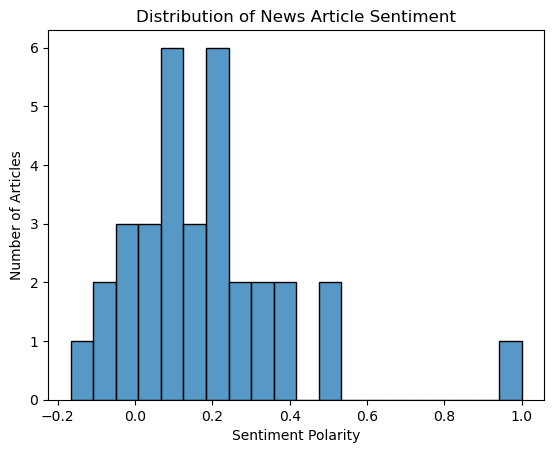

In [22]:
sns.histplot(data=df, x="polarity", bins=20)

plt.title("Distribution of News Article Sentiment")
plt.xlabel("Sentiment Polarity")
plt.ylabel("Number of Articles")

The histogram shows the distribution of sentiment polarity scores across the collected news articles. The x-axis give us the polarity scores, which range from -0.2 to 1; (-0.2, 1), while the y-axis represents the number of articles within each range. This histogram helps identify whether the collected news articles tend to have more positive, negative, or neutral sentiment.